# QuantStream — kết quả nghiên cứu đã chạy

Notebook đọc artifacts của các lượt train thật, không tự fit lại model. Dataset là BTC/USDT và ETH/USDT, nến 1 giờ. TCN được chọn bằng ba fold validation trước khi mở final holdout. Kết quả test âm sau phí được giữ nguyên.

**Mục tiêu học:** hiểu feature/label, temporal split, training, backtesting và vì sao accuracy hơi trên 50% chưa chứng minh chiến lược có lợi nhuận.

In [1]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# Notebook có thể mở từ thư mục gốc hoặc thư mục notebooks.
ROOT = Path.cwd()
if not (ROOT / 'config.json').exists():
    ROOT = ROOT.parent
cfg = json.loads((ROOT / 'config.json').read_text())
run = ROOT / json.loads((ROOT / 'artifacts/latest_run.json').read_text())['run']
quality = json.loads((ROOT / 'data/processed/data_quality.json').read_text())
split = json.loads((ROOT / 'data/processed/split_plan.json').read_text())
report = json.loads((run / 'final_report.json').read_text())
bars = pd.read_parquet(ROOT / 'data/processed/bars.parquet')
# Paper runtime có thể thêm dữ liệu mới; chỉ đọc khoảng lịch sử của thí nghiệm này.
historical_end = pd.Timestamp(split['end'])
bars = bars[bars.timestamp < historical_end]
features = pd.read_parquet(ROOT / 'data/processed/features.parquet')
display(bars.groupby('symbol').agg(candles=('close','size'), first=('timestamp','min'), last=('timestamp','max')))
display(pd.DataFrame([{k:v for k,v in quality.items() if k != 'gaps'}]))
print('Khoảng trống dữ liệu:', quality['gaps'])

Khoảng trống dữ liệu: [{'symbol': 'BTCUSDT', 'after': '2023-03-24T11:00:00+00:00', 'missing_bars': 2}, {'symbol': 'ETHUSDT', 'after': '2023-03-24T11:00:00+00:00', 'missing_bars': 2}]


,candles,first,last
symbol,,,
BTCUSDT,33598,2023-01-01 00:00:00+00:00,2026-10-31 23:00:00+00:00
ETHUSDT,33598,2023-01-01 00:00:00+00:00,2026-10-31 23:00:00+00:00


,input_rows,valid_rows,quarantine_rows,duplicate_rows
0,67198,67196,2,0


## Feature và nhãn

Tất cả feature lấy từ nến đã đóng. Chờ thêm một giờ để xử lý rồi mới vào ở giá mở nến kế tiếp. Giữ vị thế 4 giờ. Nhãn là `exit_close / entry_open - 1`; phí và slippage được tính trong simulator.

Không dùng scaler fit trên toàn dữ liệu. Nến thiếu làm indicators/sequence khởi động lại.

In [2]:
display(features[['symbol','decision_time','entry_time','label_end_time','ret_1','rsi_14','target_return']].head(8))
display(pd.DataFrame(split['folds']))
print('Final holdout bắt đầu:', split['test_start'])
print('Rule:', split['rule'])

Final holdout bắt đầu: 2026-01-25T17:00:00+00:00
Rule: train.label_end_time < validation_start; validation.label_end_time < validation_end


,symbol,decision_time,entry_time,label_end_time,ret_1,rsi_14,target_return
0,BTCUSDT,2023-01-03 01:00:00+00:00,2023-01-03 02:00:00+00:00,2023-01-03 06:00:00+00:00,0.001362,0.538669,0.002872
1,ETHUSDT,2023-01-03 01:00:00+00:00,2023-01-03 02:00:00+00:00,2023-01-03 06:00:00+00:00,0.001276,0.593477,0.003072
2,BTCUSDT,2023-01-03 02:00:00+00:00,2023-01-03 03:00:00+00:00,2023-01-03 07:00:00+00:00,-0.001078,0.505857,0.003211
3,ETHUSDT,2023-01-03 02:00:00+00:00,2023-01-03 03:00:00+00:00,2023-01-03 07:00:00+00:00,-0.001161,0.558806,0.002133
4,BTCUSDT,2023-01-03 03:00:00+00:00,2023-01-03 04:00:00+00:00,2023-01-03 08:00:00+00:00,-0.000214,0.499356,0.002272
5,ETHUSDT,2023-01-03 03:00:00+00:00,2023-01-03 04:00:00+00:00,2023-01-03 08:00:00+00:00,0.000066,0.560375,0.000847
6,BTCUSDT,2023-01-03 04:00:00+00:00,2023-01-03 05:00:00+00:00,2023-01-03 09:00:00+00:00,0.001066,0.531638,0.001799
7,ETHUSDT,2023-01-03 04:00:00+00:00,2023-01-03 05:00:00+00:00,2023-01-03 09:00:00+00:00,0.001128,0.587438,0.001714


,validation_start,validation_end
0,2024-11-05T03:00:00+00:00,2025-04-02T23:00:00+00:00
1,2025-04-02T23:00:00+00:00,2025-08-29T20:00:00+00:00
2,2025-08-29T20:00:00+00:00,2026-01-25T17:00:00+00:00


## So sánh model trên development

Ridge, Logistic và hai cấu hình XGBoost được đánh giá cùng 3 fold. TCN tự viết bằng PyTorch, cũng dùng 3 fold. Epoch được chọn bằng validation MSE; sau đó chọn threshold chiến lược trên development. Số giao dịch tối thiểu là 20 gộp qua các fold. Đây là kết quả dùng để chọn model, không phải kết quả final test.

,model,threshold,eligible,mean_validation_sharpe,mean_validation_return,worst_validation_drawdown,validation_trades
16,tcn,0.0060,True,0.452915,0.016178,-0.085716,124
0,ridge,0.0060,True,0.443967,0.016418,-0.036583,20
1,xgboost_d5,0.0060,True,-0.280987,-0.022007,-0.140708,166
2,xgboost_d3,0.0060,True,-0.334353,-0.028894,-0.155453,97
3,xgboost_d3,0.0030,True,-0.510931,-0.026453,-0.151192,269
4,xgboost_d5,0.0030,True,-0.666660,-0.060121,-0.165400,481
5,ridge,0.0030,True,-0.765733,-0.050935,-0.125511,147
6,xgboost_d3,0.0015,True,-1.573866,-0.116657,-0.196338,592
7,logistic,0.6000,True,-1.986806,-0.103005,-0.181812,234
8,ridge,0.0015,True,-2.031231,-0.074886,-0.202037,394


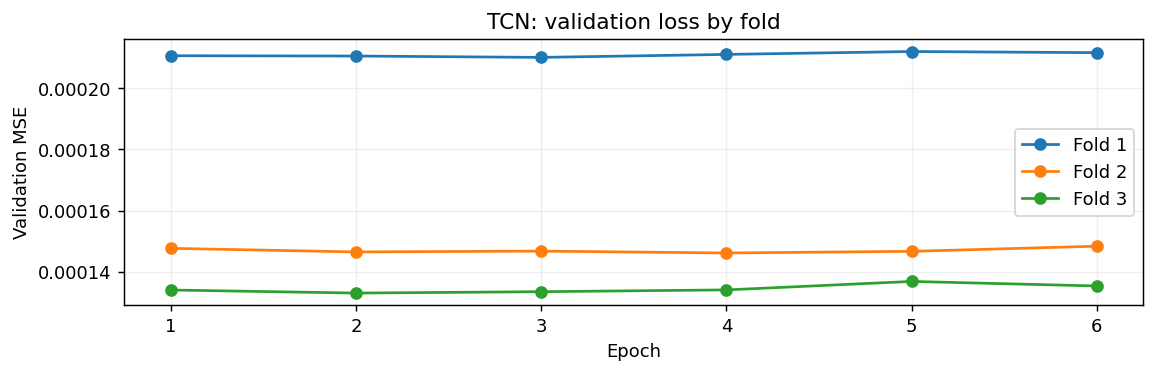

In [3]:
comparison = pd.DataFrame(json.loads((run / 'comparison.json').read_text())).drop(columns=['last_fold','selection_score'])
tcn = json.loads((ROOT / 'artifacts/tcn_training/tcn_metadata.json').read_text())
tcn_row = {'model':'tcn', 'threshold':tcn['threshold']}
tcn_row.update({k:v for k,v in tcn['selection'].items() if k in comparison.columns})
comparison = pd.concat([comparison,pd.DataFrame([tcn_row])],ignore_index=True)
display(comparison.sort_values('mean_validation_sharpe',ascending=False))
history = []
for fold in tcn['history']:
    for epoch in fold['epochs']:
        history.append({'fold':fold['fold'] + 1, **epoch})
history = pd.DataFrame(history)
fig, ax = plt.subplots(figsize=(9,3))
for fold, group in history.groupby('fold'):
    ax.plot(group.epoch,group.validation_mse,marker='o',label=f'Fold {fold}')
ax.set(xlabel='Epoch',ylabel='Validation MSE',title='TCN: validation loss by fold')
ax.legend(); ax.grid(alpha=.2); plt.tight_layout(); plt.show()

## Final holdout — chỉ mở sau khi khóa lựa chọn

Các con số dưới đây đã tính phí 10 bps và slippage 5 bps **mỗi chiều**, chờ khớp 1 giờ, giữ 4 giờ. Halt theo drawdown 20% của mỗi phần vốn tài sản, kiểm tra ở giá đóng nến. Buy-and-hold là benchmark giữ liên tục; EMA dùng cùng cơ chế giữ 4 giờ và risk rules với model.

,strategy,total_return,sharpe_hourly_estimate,max_drawdown,trades,win_rate,turnover
0,TCN,-0.144567,-2.060140,-0.170877,46,0.260870,80.687261
1,Buy and hold,-0.164116,-0.298106,-0.404594,2,0.000000,3.471442
2,EMA,-0.198055,-3.501635,-0.199253,88,0.318182,152.954454


,directional_accuracy,mae_return
0,0.514183,0.007089


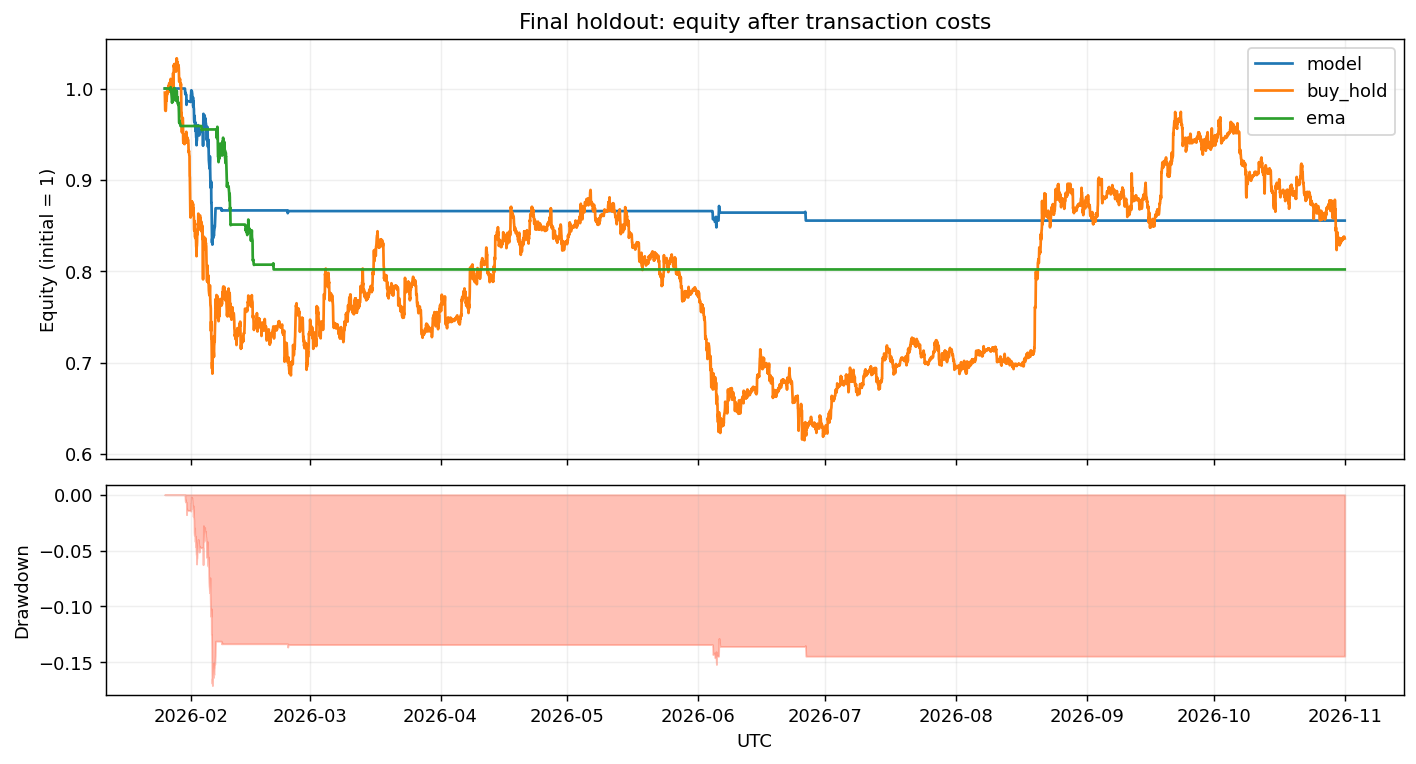

,symbol,entry_time,entry_price,entry_notional,entry_fee,capital_before,exit_time,exit_price,exit_notional,exit_fee,net_return,exit_reason
0,BTCUSDT,2026-02-04T01:00:00+00:00,75948.835440,0.949051,0.000949,1.000000,2026-02-04T05:00:00+00:00,76441.510125,0.955207,0.000955,0.004476,horizon
1,BTCUSDT,2026-02-04T19:00:00+00:00,73462.682985,0.953086,0.000953,1.004252,2026-02-04T23:00:00+00:00,72507.108310,0.940689,0.000941,-0.014980,horizon
2,BTCUSDT,2026-02-04T23:00:00+00:00,72579.651690,0.939523,0.000940,0.989961,2026-02-05T03:00:00+00:00,71418.712780,0.924495,0.000924,-0.017961,horizon
3,BTCUSDT,2026-02-05T03:00:00+00:00,71490.167220,0.923492,0.000923,0.973069,2026-02-05T07:00:00+00:00,70916.034245,0.916076,0.000916,-0.010013,horizon
4,BTCUSDT,2026-02-05T07:00:00+00:00,70986.985755,0.914708,0.000915,0.963813,2026-02-05T11:00:00+00:00,70822.700935,0.912591,0.000913,-0.004308,horizon
5,BTCUSDT,2026-02-05T11:00:00+00:00,70893.559065,0.910964,0.000911,0.959869,2026-02-05T15:00:00+00:00,69370.057620,0.891388,0.000891,-0.023445,horizon
6,BTCUSDT,2026-02-05T17:00:00+00:00,68329.297575,0.890675,0.000891,0.938490,2026-02-05T21:00:00+00:00,63743.782165,0.830902,0.000831,-0.068973,horizon
7,BTCUSDT,2026-02-05T21:00:00+00:00,63807.547830,0.832314,0.000832,0.876996,2026-02-06T01:00:00+00:00,63477.635305,0.828010,0.000828,-0.007158,horizon
8,BTCUSDT,2026-02-06T01:00:00+00:00,63541.154700,0.826654,0.000827,0.871032,2026-02-06T05:00:00+00:00,64873.387080,0.843986,0.000844,0.018927,horizon
9,BTCUSDT,2026-02-06T05:00:00+00:00,64937.992770,0.841517,0.000842,0.886693,2026-02-06T09:00:00+00:00,64862.602475,0.840540,0.000841,-0.003157,horizon


In [4]:
rows=[]
for name,key in [('TCN','strategy'),('Buy and hold','buy_hold'),('EMA','ema')]:
    rows.append({'strategy':name,**report[key]})
display(pd.DataFrame(rows).drop(columns='note'))
display(pd.DataFrame([report['prediction']]))
curve=pd.read_parquet(run/'test_equity.parquet')
fig,axes=plt.subplots(2,1,figsize=(11,6),sharex=True,gridspec_kw={'height_ratios':[2,1]})
for column in ['model','buy_hold','ema']:
    axes[0].plot(curve.timestamp,curve[column],label=column)
axes[0].set(ylabel='Equity (initial = 1)',title='Final holdout: equity after transaction costs')
axes[0].legend(); axes[0].grid(alpha=.2)
dd=curve.model/curve.model.cummax().clip(lower=1)-1
axes[1].fill_between(curve.timestamp,dd,0,color='tomato',alpha=.4)
axes[1].set(ylabel='Drawdown',xlabel='UTC'); axes[1].grid(alpha=.2)
plt.tight_layout(); plt.show()
display(pd.read_parquet(run/'test_trades.parquet').head(10))

## Fine-tuning pretrained bằng LoRA

Lượt kiểm chứng đã fine-tune Chronos-2 trên log-price quá khứ trong train, rồi so sánh trước/sau trên cùng 512 cửa sổ validation lấy mẫu cố định. Không đưa future OHLCV vào model. Phần này exploratory vì chưa xác minh trùng lặp dữ liệu pretraining; không dùng để chọn champion hoặc mở final test.

In [5]:
chronos=json.loads((ROOT/'artifacts/chronos_200/chronos_report.json').read_text())
display(pd.DataFrame([
    {'mode':'zero_shot','mae':chronos['zero_shot_mae'],'directional_accuracy':chronos['zero_shot_directional_accuracy']},
    {'mode':'LoRA_200_steps','mae':chronos['finetuned_mae'],'directional_accuracy':chronos['finetuned_directional_accuracy']}
]))
print('Base revision:',chronos['resolved_revision'])
print('Device used:',chronos['device'])
print('Pretraining cutoff verified:',chronos['pretraining_data_cutoff_verified'])

Base revision: 29ec3766d36d6f73f0696f85560a422f50e8498c
Device used: cpu
Pretraining cutoff verified: False


,mode,mae,directional_accuracy
0,zero_shot,0.007836,0.501953
1,LoRA_200_steps,0.007916,0.498047


## Kết luận

Pipeline train và fine-tuning đã chạy được, nhưng chiến lược TCN hiện vẫn lỗ trên final holdout; LoRA cũng chưa cải thiện MAE ở lượt này. Điều này không được đổi thành tuyên bố model thành công về giao dịch.

Các hướng nghiên cứu tiếp: kiểm tra hypothesis theo regime, calibration ở nhóm tín hiệu lớn, mức độ nhạy với chi phí và uncertainty qua các block thời gian. Hypothesis/model mới phải được đánh giá trên giai đoạn tương lai mới; final test đang có đã được xem.

Để trình diễn: giải thích data quality, nhãn đúng với thời điểm khớp, purge tại ranh giới, kết quả validation khác test và cách monitoring phát hiện thay đổi. Notebook 02 và 03 cho phép bạn chạy lại phần training trên tài khoản Kaggle của mình.